<font size="6" color="#43A832"><b>What Makes a Music Artist Successful?</b></font>

<font size="4" color="#000000"><b>Programming for Data Science — Group Project 2026/2027</b></font>

<font size="4" color="#43A832"><b>Group Members</b></font>

<font size="3" color="#000000">

- **José Jesus** — 20251389
- **Lara Barradas** — 20251397
- **Lara Manso** — 20251364
- **Zahra Ahamed** — 20251382

</font>

<font size="4" color="#43A832"><b>Table of Contents</b></font>

<font size="3" color="#000000">

1. **Introduction**
2. **Data Wrangling and Analysis**
   - 2.1 Data Quality and Cleaning
   - 2.2 Basic Exploratory Analysis
   - 2.3 Data Update Analysis
   - 2.4 Career Length and Collaborations
   - 2.5 Additional Insights
3. **Advanced Topic — Building Interactive Maps**
   - 3.1 Web Scraping
   - 3.2 Interactive Maps
4. **Data Science in Action**
5. **Conclusions**

</font>

<font size="4" color="#43A832"><b>1. Introduction</b></font>

<font size="3" color="#000000">

Music streaming platforms generate large amounts of data that can be used to better understand artist popularity and streaming trends. This project aims to explore the characteristics and streaming performance of some of the world's most-streamed artists and identify patterns that may help explain their success.

Throughout the project, the dataset will be cleaned, explored, and analyzed using Python. The analysis will examine factors such as genre, country of origin, language, career length, and solo and collaborative streams. Web scraping and interactive maps will also be used to explore where artists come from and how streams are distributed worldwide.

</font>

<font size="4" color="#43A832"><b>2. Data Wrangling and Analysis</b></font>

<font size="3" color="#000000"><b>2.1 Data Quality and Cleaning</b></font>

In [26]:
#Import the necessary libraries

import pandas as pd
import matplotlib.pyplot as plt

In [27]:
#Loading the dataset

artist_streams = pd.read_csv('artist_streams.csv', index_col = 0)
artist_streams

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
Artist ID,,,,,,,,,,,,,,
0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01 00:00:00,2026.0
1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01 00:00:00,2026.0
2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01 00:00:00,2026.0
3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01 00:00:00,2026.0
4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01 00:00:00,2026.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
496,The Marías,NaN,United States,English,Pop,Group,2017.0,7029.1,5774.4,1261.4,5705.9,1323.2,2026-07-01 00:00:00,2026.0
497,Limp Bizkit,Male,United States,English,Nu Metal,Group,1997.0,7018.9,7018.4,5.4,6806.0,212.9,2026-07-01 00:00:00,2026.0
498,Korn,Male,United States,English,Metal,Group,1994.0,6976.4,4188.4,2798.5,6414.9,561.5,2026-07-01 00:00:00,2026.0


In [28]:
#Check the dataset structure, data types and missing values

artist_streams.info()

<class 'pandas.core.frame.DataFrame'>
Index: 511 entries, 0 to 500
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Artist Name            510 non-null    object 
 1   Sex                    486 non-null    object 
 2   Country of Origin      510 non-null    object 
 3   Primary Language       510 non-null    object 
 4   Primary Genre          510 non-null    object 
 5   Artist Type            510 non-null    object 
 6   Debut Year             510 non-null    float64
 7   Total Streams          505 non-null    float64
 8   Lead Streams           504 non-null    float64
 9   Feature Streams        499 non-null    float64
 10  Solo Streams           506 non-null    float64
 11  Collaborative Streams  509 non-null    float64
 12  Update Date            510 non-null    object 
 13  Year                   510 non-null    float64
dtypes: float64(7), object(7)
memory usage: 59.9+ KB


In [29]:
#Identify all duplicated rows in the dataset

artist_streams[artist_streams.duplicated(keep = False)]

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
Artist ID,,,,,,,,,,,,,,
45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01 00:00:00,2026.0
45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01 00:00:00,2026.0
140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01 00:00:00,2026.0
140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01 00:00:00,2026.0
218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01 00:00:00,2026.0
218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01 00:00:00,2026.0
221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01 00:00:00,2026.0
221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01 00:00:00,2026.0
263,Zedd,Male,Russia,English,EDM,Solo,2010.0,11481.4,11486.5,0.0,235.7,11245.7,2026-07-01 00:00:00,2026.0


In [30]:
#Remove duplicate rows and verify

artist_streams = artist_streams.drop_duplicates()
artist_streams.duplicated().sum()

np.int64(0)

In [31]:
#Remove rows where all column values are missing

artist_streams = artist_streams.dropna(how = "all")
artist_streams

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
Artist ID,,,,,,,,,,,,,,
0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01 00:00:00,2026.0
1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01 00:00:00,2026.0
2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01 00:00:00,2026.0
3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01 00:00:00,2026.0
4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01 00:00:00,2026.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,The Cure,Male,United Kingdom,English,Rock,Group,1979.0,7034.1,7035.0,3.3,6940.1,94.0,2026-07-01 00:00:00,2026.0
496,The Marías,NaN,United States,English,Pop,Group,2017.0,7029.1,5774.4,1261.4,5705.9,1323.2,2026-07-01 00:00:00,2026.0
497,Limp Bizkit,Male,United States,English,Nu Metal,Group,1997.0,7018.9,7018.4,5.4,6806.0,212.9,2026-07-01 00:00:00,2026.0


In [32]:
#Identify artists with missing Sex values and check their Artist Type

artist_streams[artist_streams["Sex"].isnull()][["Artist Name", "Artist Type"]]

,Artist Name,Artist Type
Artist ID,,
38,Maroon 5,Group
45,Linkin Park,Group
59,One Direction,Group
89,Disney,Group
91,Red Hot Chili Peppers,Group
94,OneRepublic,Group
140,Fleetwood Mac,Group
155,Black Eyed Peas,Group
214,Cigarettes After Sex,Group


In [33]:
#Replace missing Sex values with "Not Applicable"

artist_streams.loc[artist_streams["Sex"].isnull(), "Sex"] = "Not Applicable"
artist_streams["Sex"].isnull().sum()

np.int64(0)

In [34]:
#Identify artists with missing values in streaming metrics

stream_columns = ["Total Streams", "Lead Streams", "Feature Streams", "Solo Streams", "Collaborative Streams"]

artist_streams.loc[
    artist_streams[stream_columns].isnull().any(axis = 1),
    ["Artist Name"] + stream_columns
]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
Artist ID,,,,,,
16,Future,53951.5,27879.0,26072.5,NaN,41304.0
46,Peso Pluma,NaN,18699.1,14501.2,3938.3,29241.5
56,Harry Styles,29449.0,29462.8,NaN,29449.0,0.0
106,Kygo,19707.8,NaN,1883.3,250.7,19457.1
123,Sean Paul,18203.3,NaN,8539.4,4460.6,13742.7
130,Bebe Rexha,17440.2,NaN,11512.1,2784.0,14656.2
140,Fleetwood Mac,16577.5,16577.5,NaN,16567.4,10.1
167,A.R. Rahman,15240.4,10857.5,4397.5,NaN,14645.5
176,ROSALÍA,14558.4,10084.0,NaN,5316.8,9241.6


In [35]:
#Fill missing streaming values using the relationships between stream metrics

artist_streams["Total Streams"] = artist_streams["Total Streams"].fillna(
    artist_streams["Lead Streams"] + artist_streams["Feature Streams"])

artist_streams["Lead Streams"] = artist_streams["Lead Streams"].fillna(
    artist_streams["Total Streams"] - artist_streams["Feature Streams"])

artist_streams["Feature Streams"] = artist_streams["Feature Streams"].fillna(
    artist_streams["Total Streams"] - artist_streams["Lead Streams"])

artist_streams["Solo Streams"] = artist_streams["Solo Streams"].fillna(
    artist_streams["Total Streams"] - artist_streams["Collaborative Streams"])

artist_streams["Collaborative Streams"] = artist_streams["Collaborative Streams"].fillna(
    artist_streams["Total Streams"] - artist_streams["Solo Streams"])

In [36]:
#Check missing values

artist_streams.isnull().sum()

Artist Name              0
Sex                      0
Country of Origin        0
Primary Language         0
Primary Genre            0
Artist Type              0
Debut Year               0
Total Streams            0
Lead Streams             0
Feature Streams          0
Solo Streams             0
Collaborative Streams    0
Update Date              0
Year                     0
dtype: int64

In [37]:
#Identify artists with negative streaming values

artist_streams.loc[(artist_streams[stream_columns] < 0).any(axis = 1),
                   ["Artist Name"] + stream_columns]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
Artist ID,,,,,,
56,Harry Styles,29449.0,29462.8,-13.8,29449.0,0.0
326,Maná,9914.4,9921.1,-6.7,7817.7,2096.7


In [38]:
#Check inconsistencies between total streams and their components

artist_streams["Lead_Feature_Diff"] = (artist_streams["Total Streams"]
                                       - artist_streams["Lead Streams"]
                                       - artist_streams["Feature Streams"])

artist_streams["Solo_Collab_Diff"] = (artist_streams["Total Streams"]
                                      - artist_streams["Solo Streams"]
                                      - artist_streams["Collaborative Streams"])

print("Lead + Feature inconsistencies:",
      (artist_streams["Lead_Feature_Diff"].abs() > 0.11).sum())

print("Solo + Collaborative inconsistencies:",
      (artist_streams["Solo_Collab_Diff"].abs() > 0.11).sum())

Lead + Feature inconsistencies: 383
Solo + Collaborative inconsistencies: 4


In [39]:
#Identify artists with inconsistencies between total, solo and collaborative streams

artist_streams.loc[artist_streams["Solo_Collab_Diff"].abs() > 0.11,
                   ["Artist Name", "Total Streams", "Solo Streams",
                    "Collaborative Streams", "Solo_Collab_Diff"]]

,Artist Name,Total Streams,Solo Streams,Collaborative Streams,Solo_Collab_Diff
Artist ID,,,,,
46,Peso Pluma,33200.3,3938.3,29241.5,20.5
290,blink-182,10764.2,10584.7,175.7,3.8
384,Fetty Wap,8567.5,3239.0,5325.5,3.0
475,Thomas Rhett,7350.3,5340.9,1996.6,12.8


In [40]:
#Check unique values in categorical columns

categorical_columns = ["Sex", "Country of Origin", "Primary Language",
                       "Primary Genre", "Artist Type"]

for col in categorical_columns:
    print(f"\n{col}:")
    print(artist_streams[col].unique())


Sex:
['Male' 'Female' 'Not Applicable']

Country of Origin:
['Canada' 'United States' 'United Kingdom' 'Barbados' 'Colombia'
 'South Korea' 'Trinidad and Tobago' 'France' 'India' 'Scotland' 'Mexico'
 'Australia' 'Germany' 'Cuba' 'Sweden' 'Norway' 'Panama' 'Brazil'
 'Netherlands' 'Jamaica' 'Senegal' 'Ireland' 'Argentina' 'Spain' 'Japan'
 'New Zealand' 'Morocco' 'Chile' 'Russia' 'Nigeria' 'South Africa'
 'Venezuela' 'Italy' 'Dominican Republic' 'Belgium' 'DR Congo' 'Nepal'
 'Pakistan' 'Guatemala' 'Austria' 'Philippines' 'Denmark' 'Iceland']

Primary Language:
['English' 'Spanish' 'Korean' 'Hindi' 'German' 'Portuguese' 'Tamil'
 'French' 'Italian' 'Urdu' 'Punjabi']

Primary Genre:
['Hip-Hop' 'Pop' 'Reggaeton' 'R&B' 'K-Pop' 'Rock' 'Alternative' 'EDM'
 'Filmi' 'Latin' 'Regional Mexican' 'Country' 'Spoken Word' 'Soundtrack'
 'Bachata' 'Sertanjeo' 'Reggae' 'Folk' 'Metal' 'Afrobeats' 'Soul'
 "Children's Music" 'Nu Metal']

Artist Type:
['Solo' 'Group']


In [41]:
#Check for invalid debut years and extraction years

artist_streams.loc[(artist_streams["Debut Year"] > artist_streams["Year"]) |
                   (artist_streams["Debut Year"] < 1900) |
                   (artist_streams["Year"] > 2026),
                   ["Artist Name", "Debut Year", "Year"]]

,Artist Name,Debut Year,Year
Artist ID,,,


In [42]:
#Check for invalid or inconsistent update dates

dates = pd.to_datetime(artist_streams["Update Date"], errors = "coerce")

artist_streams.loc[dates.isna() |
                   (dates.dt.year > artist_streams["Year"]),
                   ["Artist Name", "Update Date", "Year"]]

,Artist Name,Update Date,Year
Artist ID,,,


In [43]:
#Check original streaming values for Harry Styles and Maná

original_data = pd.read_csv("artist_streams.csv", index_col=0)

original_data.loc[original_data["Artist Name"].isin(["Harry Styles", "Maná"]),
                  ["Artist Name", "Total Streams", "Lead Streams",
                   "Feature Streams", "Solo Streams", "Collaborative Streams"]]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
Artist ID,,,,,,
56,Harry Styles,29449.0,29462.8,NaN,29449.0,0.0
326,Maná,9914.4,9921.1,NaN,7817.7,2096.7


In [44]:
#Replace invalid negative feature streams with missing values

artist_streams.loc[artist_streams["Feature Streams"] < 0,
                   "Feature Streams"] = float("nan")

artist_streams.loc[artist_streams["Artist Name"].isin(["Harry Styles", "Maná"]),
                   ["Artist Name", "Feature Streams"]]

,Artist Name,Feature Streams
Artist ID,,
56,Harry Styles,NaN
326,Maná,NaN


In [45]:
#Recalculate differences and convert them to percentages

artist_streams["Lead_Feature_Diff"] = (artist_streams["Total Streams"]
                                       - artist_streams["Lead Streams"]
                                       - artist_streams["Feature Streams"])

artist_streams["Lead_Feature_Diff_Pct"] = (artist_streams["Lead_Feature_Diff"].abs()
                                           / artist_streams["Total Streams"] * 100)

artist_streams["Lead_Feature_Diff_Pct"].describe()

count    498.000000
mean       0.049829
std        0.063270
min        0.000000
25%        0.013594
50%        0.036123
75%        0.058733
max        0.545029
Name: Lead_Feature_Diff_Pct, dtype: float64

In [46]:
#Calculate percentage differences between total, solo, and collaborative streams

artist_streams["Solo_Collab_Diff_Pct"] = (artist_streams["Solo_Collab_Diff"].abs()
                                          / artist_streams["Total Streams"] * 100)

artist_streams.loc[artist_streams["Solo_Collab_Diff"].abs() > 0.11,
                   ["Artist Name", "Solo_Collab_Diff", "Solo_Collab_Diff_Pct"]]

,Artist Name,Solo_Collab_Diff,Solo_Collab_Diff_Pct
Artist ID,,,
46,Peso Pluma,20.5,0.061746
290,blink-182,3.8,0.035302
384,Fetty Wap,3.0,0.035016
475,Thomas Rhett,12.8,0.174143


In [47]:
#Verify remaining missing values and negative streaming values

print("Missing values:")
print(artist_streams.isnull().sum())

print("\nNegative streaming values:")
print((artist_streams[stream_columns] < 0).sum())

Missing values:
Artist Name              0
Sex                      0
Country of Origin        0
Primary Language         0
Primary Genre            0
Artist Type              0
Debut Year               0
Total Streams            0
Lead Streams             0
Feature Streams          2
Solo Streams             0
Collaborative Streams    0
Update Date              0
Year                     0
Lead_Feature_Diff        2
Solo_Collab_Diff         0
Lead_Feature_Diff_Pct    2
Solo_Collab_Diff_Pct     0
dtype: int64

Negative streaming values:
Total Streams            0
Lead Streams             0
Feature Streams          0
Solo Streams             0
Collaborative Streams    0
dtype: int64


In [48]:
#Remove temporary columns used for data quality checks

artist_streams = artist_streams.drop(columns=["Lead_Feature_Diff",
                                              "Solo_Collab_Diff",
                                              "Lead_Feature_Diff_Pct",
                                              "Solo_Collab_Diff_Pct"])

artist_streams.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Artist Name            500 non-null    object 
 1   Sex                    500 non-null    object 
 2   Country of Origin      500 non-null    object 
 3   Primary Language       500 non-null    object 
 4   Primary Genre          500 non-null    object 
 5   Artist Type            500 non-null    object 
 6   Debut Year             500 non-null    float64
 7   Total Streams          500 non-null    float64
 8   Lead Streams           500 non-null    float64
 9   Feature Streams        498 non-null    float64
 10  Solo Streams           500 non-null    float64
 11  Collaborative Streams  500 non-null    float64
 12  Update Date            500 non-null    object 
 13  Year                   500 non-null    float64
dtypes: float64(7), object(7)
memory usage: 58.6+ KB


In [49]:
#Export the cleaned dataset

artist_streams.to_csv("artist_streams_cleaned.csv", index = False)

<font size="3" color="#000000"><b>Data Cleaning Summary</b></font>

<font size="3" color="#000000">

**Duplicates:** Duplicate and fully empty rows were removed, reducing the dataset from 511 to 500 records.

**Missing Values:** Missing Sex values were replaced with "Not Applicable" for groups. Missing streaming values were reconstructed using the relationships between stream metrics.

**Invalid Values:** Two negative Feature Streams values were replaced with NaN, as their correct values could not be reliably determined.

**Inconsistencies:** Small relative differences were found between Total Streams and its components. The original values were preserved because the discrepancies were minor and the correct values could not be reliably identified.

**Final Validation:** The cleaned dataset contains 500 records and 14 columns, with no negative streaming values and only two remaining missing values.

</font>

<font size="3" color="#000000"><b>2.2 Basic Exploratory Analysis</b></font>

In [50]:
#Count unique artists and pop artists

print("Unique artists:", artist_streams["Artist Name"].nunique())
print("Pop artists:", (artist_streams["Primary Genre"] == "Pop").sum())

Unique artists: 500
Pop artists: 102


In [51]:
#Identify the most common music genre

artist_streams["Primary Genre"].value_counts()

Primary Genre
Hip-Hop             115
Pop                 102
Rock                 60
Reggaeton            43
R&B                  31
Latin                30
EDM                  22
Regional Mexican     19
K-Pop                11
Filmi                11
Country              10
Alternative           9
Sertanjeo             9
Metal                 8
Folk                  4
Soundtrack            3
Bachata               3
Soul                  3
Reggae                2
Afrobeats             2
Spoken Word           1
Children's Music      1
Nu Metal              1
Name: count, dtype: int64

In [52]:
#Identify the most common country

artist_streams["Country of Origin"].value_counts()

Country of Origin
United States          265
United Kingdom          55
Mexico                  27
Canada                  18
Colombia                16
Brazil                  15
India                   13
South Korea             11
Argentina                9
Australia                7
Germany                  7
Spain                    6
Sweden                   5
France                   5
Ireland                  4
Italy                    3
Japan                    2
Scotland                 2
Jamaica                  2
Nigeria                  2
Dominican Republic       2
Norway                   2
Netherlands              2
Barbados                 1
Trinidad and Tobago      1
Panama                   1
Cuba                     1
Morocco                  1
New Zealand              1
Senegal                  1
Chile                    1
South Africa             1
Russia                   1
Venezuela                1
Belgium                  1
DR Congo                 1
Nepal     

In [53]:
#Identify the three most common languages

artist_streams["Primary Language"].value_counts().head(3)

Primary Language
English       340
Spanish       105
Portuguese     15
Name: count, dtype: int64

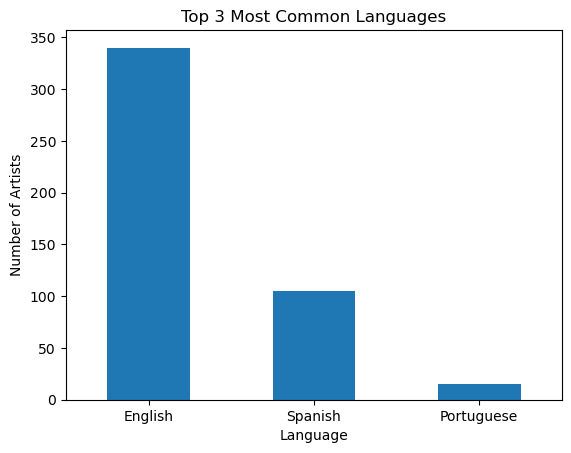

In [54]:
#Plot the three most common languages

top_languages = artist_streams["Primary Language"].value_counts().head(3)
top_languages.plot(kind = "bar")

plt.title("Top 3 Most Common Languages")
plt.xlabel("Language")
plt.ylabel("Number of Artists")
plt.xticks(rotation=0)
plt.show()


<font size="3" color="#000000"><b>Exploratory Analysis Summary</b></font>

<font size="3" color="#000000">

**Unique Artists:** The dataset contains 500 unique artists, of which 102 (20.4%) are classified as Pop artists.

**Most Common Genre:** Hip-Hop is the most frequent genre, with 115 artists (23%), followed by Pop (102) and Rock (60).

**Most Common Country:** The United States is the most represented country, with 265 artists (53%), followed by the United Kingdom (55) and Mexico (27).

**Most Common Languages:** English is the most common primary language, with 340 artists (68%), followed by Spanish (105) and Portuguese (15), as illustrated in the bar chart above.

</font>

<font size="3" color="#000000"><b>2.3 Data Update Analysis</b></font>

In [55]:
#Convert update dates to datetime

artist_streams["Update Date"] = pd.to_datetime(artist_streams["Update Date"])
artist_streams["Update Date"].head()

Artist ID
0   2026-07-01
1   2026-07-01
2   2026-07-01
3   2026-07-01
4   2026-07-01
Name: Update Date, dtype: datetime64[ns]

In [56]:
#Find the most recent and oldest update dates

print("Most recent update:", artist_streams["Update Date"].max())
print("Oldest update:", artist_streams["Update Date"].min())

Most recent update: 2026-07-01 00:00:00
Oldest update: 2025-07-01 00:00:00


In [57]:
#Calculate days since the most recent and oldest updates

today = pd.Timestamp.today().normalize()

print("Days since most recent update:",
      (today - artist_streams["Update Date"].max()).days)
print("Days since oldest update:",
      (today - artist_streams["Update Date"].min()).days)

Days since most recent update: 130
Days since oldest update: 495


In [58]:
#Identify artists with stream counts last updated before the end of 2025

outdated_artists = artist_streams[artist_streams["Update Date"] < "2026-01-01"]

print("Number of outdated artists:", len(outdated_artists))

outdated_artists[["Artist Name", "Update Date"]]

Number of outdated artists: 10


,Artist Name,Update Date
Artist ID,,
109,Quavo,2025-07-01
175,Gucci Mane,2025-07-01
193,Grupo Frontera,2025-07-01
260,Elvis Presley,2025-07-01
353,Teddy Swims,2025-07-01
381,Alejandro Fernández,2025-07-01
387,SEVENTEEN,2025-07-01
439,ScHoolboy Q,2025-07-01
478,Kane Brown,2025-07-01


<font size="3" color="#000000"><b>Data Update Analysis Summary</b></font>

<font size="3" color="#000000">

**Most Recent Update:** The most recent update occurred on July 1, 2026.

**Oldest Update:** The oldest update occurred on July 1, 2025.

**Outdated Stream Counts:** A total of 10 artists (2% of the dataset) have stream counts that were last updated before the end of 2025.

**Artists Requiring Updates:** Quavo, Gucci Mane, Grupo Frontera, Elvis Presley, Teddy Swims, Alejandro Fernández, SEVENTEEN, ScHoolboy Q, Kane Brown, and Grupo Menos É Mais.

**Conclusion:** Most artists have more recent streaming records, while these 10 artists require updated stream counts to ensure the dataset reflects more recent streaming activity.

</font>